# 06 · Inferência e inspeção das representações

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import torch
from IPython.display import display, Markdown, Image, Video
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / 'seminar_5']
            if (p / 'experiments/configs/demo.json').exists())
sys.path.insert(0, str(ROOT / 'experiments/scripts'))
import experiment as exp
torch.set_num_threads(2)
config = json.loads((ROOT / 'experiments/configs/demo.json').read_text())
protocol = json.loads((ROOT / 'experiments/results/protocol.json').read_text())
print('Demonstração conceitual MNIST/PCA/MLP. Não é reprodução de FID/CLIP LAION.')


Demonstração conceitual MNIST/PCA/MLP. Não é reprodução de FID/CLIP LAION.


Input: ruído normal e classe. Estado intermediário: latente PCA. Output: imagem 14×14. O LCM faz nova previsão limpa após reinjetar ruído. O baseline local é DDIM, não amostragem ancestral DDPM.

In [2]:
data = exp.prepare_data()
student = exp.NoiseMLP(config)
student.load_state_dict(torch.load(ROOT / 'experiments/checkpoints/lcm_k20.pt', weights_only=True)['state_dict'])
labels = torch.arange(10)
latent, history = exp.sample(student, labels, 4, 101, return_history=True)
repeated = exp.sample(student, labels, 4, 101)
assert torch.equal(latent, repeated)
pixels = exp.decode(latent, data)
print('Latente:', latent.shape, 'histórico:', history.shape, 'pixels:', pixels.shape)
print('Reprodutibilidade bit a bit da inferência nesta máquina: OK')

Latente: torch.Size([10, 32]) histórico: torch.Size([4, 10, 32]) pixels: torch.Size([10, 196])
Reprodutibilidade bit a bit da inferência nesta máquina: OK


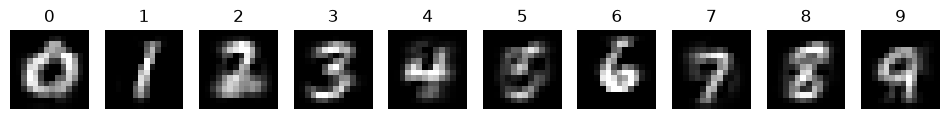

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 10, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(pixels[i].reshape(14,14), cmap='gray', vmin=0, vmax=1)
    ax.set_title(str(i))
    ax.axis('off')
plt.show()

In [4]:
display(Video(str(ROOT / 'assets/videos/LocalGeneration.mp4'), embed=True, width=850))

O vídeo usa o batch de 300 salvo na avaliação. A grade desta célula usa batch de 10 e faz nova inferência. Eles não são apresentados como a mesma execução.